# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Keysha Khoirunnisa Aulia Khotim
- **Email:** keysha.khoirunnisaak@gmail.com
- **ID Dicoding:** kyshaulia

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada jam berapa rata-rata penyewaan per jam mencapai puncak di hari kerja dibandingkan akhir pekan/libur sepanjang 2011–2012, dan berapa selisih rata-rata penyewaan pada jam puncak keduanya, sehingga tim operasional dapat menjadwalkan redistribusi sepeda antarstasiun?
- **Pertanyaan 2:** Seberapa besar (dalam %) rata-rata penyewaan harian turun saat cuaca berkabut/berawan dan hujan/salju ringan dibandingkan saat cerah, serta pada rentang suhu aktual (°C) berapa rata-rata penyewaan harian paling tinggi selama 2011–2012, agar tim dapat menjadwalkan perawatan armada dan promosi berbasis cuaca?
- **Pertanyaan 3:** Berapa pertumbuhan total penyewaan bulanan 2012 dibanding bulan yang sama di 2011 (Year-over-Year), dan berapa proporsi pengguna kasual terhadap total pengguna di setiap musim, untuk menentukan musim yang paling tepat bagi kampanye konversi pengguna kasual menjadi anggota terdaftar?

**Pemeriksaan SMART:**

| Unsur | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| Specific | Jam puncak, hari kerja vs akhir pekan/libur | Kategori cuaca dan rentang suhu aktual (°C) terhadap penyewaan harian | Pertumbuhan YoY per bulan dan proporsi pengguna kasual per musim |
| Measurable | Rata-rata sewa per jam dan selisihnya (sepeda dan %) | % penurunan penyewaan harian dan rata-rata per rentang suhu | % pertumbuhan YoY dan % pengguna kasual |
| Action-oriented | Jadwal redistribusi dan penyiapan armada | Perawatan armada saat cuaca buruk, promosi saat suhu optimal | Menentukan musim target kampanye konversi keanggotaan |
| Relevant | Ketersediaan sepeda saat permintaan tinggi menentukan pendapatan dan kepuasan | Cuaca adalah faktor eksternal utama permintaan | Pengguna terdaftar adalah sumber pendapatan yang lebih stabil |
| Time-bound | Januari 2011 – Desember 2012 | 2011–2012 | Perbandingan 2012 terhadap 2011 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Palet warna konsisten: satu warna sorot, sisanya netral
C_HIGHLIGHT = '#D1495B'   # sorotan / temuan utama
C_PRIMARY   = '#00798C'   # seri utama
C_NEUTRAL   = '#B8BFC9'   # pembanding / konteks
C_TEXT      = '#2B2D42'
C_DARK      = '#0B3C8C'   # biru tua: kategori tertinggi
C_LIGHT     = '#9DB9E0'   # biru muda: kategori lainnya

plt.rcParams.update({
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': C_TEXT, 'axes.labelcolor': C_TEXT,
    'xtick.color': C_TEXT, 'ytick.color': C_TEXT, 'text.color': C_TEXT,
    'axes.titlelocation': 'left', 'figure.dpi': 110,
})
thousand = FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.'))

## Data Wrangling

### Gathering Data

#### Load day_df (data harian) dan hour_df (data per jam)

In [2]:
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print('Ukuran day_df  :', day_df.shape)
print('Ukuran hour_df :', hour_df.shape)
day_df.head()

Ukuran day_df  : (731, 16)
Ukuran hour_df : (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 baris (2 tahun penuh, 2011 dan 2012) dan `hour_df` berisi 17.379 baris. Kolom sama kecuali `hr` yang hanya ada di data per jam.
- Kolom `season`, `weathersit`, `weekday`, `yr`, dan `mnth` masih berupa kode angka, dan `temp`, `atemp`, `hum`, `windspeed` masih ternormalisasi, sehingga perlu diterjemahkan sebelum dianalisis.

### Assessing Data

#### Identifying tipe data, missing value, dan duplikasi

In [4]:
day_df.info()
print()
hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Colu

In [5]:
print('Missing value  -> day:', day_df.isna().sum().sum(), '| hour:', hour_df.isna().sum().sum())
print('Data duplikat  -> day:', day_df.duplicated().sum(), '| hour:', hour_df.duplicated().sum())
print()
print('Tipe kolom dteday:', day_df['dteday'].dtype, '(seharusnya datetime)')

Missing value  -> day: 0 | hour: 0
Data duplikat  -> day: 0 | hour: 0

Tipe kolom dteday: str (seharusnya datetime)


#### Identifying konsistensi dan kelengkapan data

In [6]:
# Konsistensi: casual + registered harus sama dengan cnt
print('Baris cnt != casual+registered -> day :', (day_df.casual + day_df.registered != day_df.cnt).sum())
print('Baris cnt != casual+registered -> hour:', (hour_df.casual + hour_df.registered != hour_df.cnt).sum())

# Kelengkapan: seharusnya 731 hari x 24 jam = 17.544 baris
expected = len(day_df) * 24
print(f'\nBaris jam seharusnya: {expected:,} | tersedia: {len(hour_df):,} | hilang: {expected - len(hour_df):,}')
jam_per_hari = hour_df.groupby('dteday').size()
print('Hari dengan data jam tidak lengkap:', (jam_per_hari < 24).sum(), 'dari', len(jam_per_hari), 'hari')

# Apakah total harian cocok dengan penjumlahan data jam?
cek = hour_df.groupby('dteday')['cnt'].sum().reindex(day_df['dteday']).values - day_df['cnt'].values
print('Hari dengan total jam != total harian:', int((cek != 0).sum()))

Baris cnt != casual+registered -> day : 0
Baris cnt != casual+registered -> hour: 0

Baris jam seharusnya: 17,544 | tersedia: 17,379 | hilang: 165
Hari dengan data jam tidak lengkap: 76 dari 731 hari
Hari dengan total jam != total harian: 0


#### Identifying nilai tidak valid (kelembapan dan kecepatan angin)

In [7]:
# Nilai tidak valid: kelembapan (hum) bernilai 0
print('Hari dengan hum = 0  :'); display(day_df[day_df.hum == 0][['dteday','hum','temp','weathersit','cnt']])
print('Tanggal data jam dengan hum = 0:', hour_df[hour_df.hum == 0]['dteday'].unique(), '| jumlah baris:', (hour_df.hum == 0).sum())

# windspeed = 0 pada data jam
print(f"\nPersentase windspeed = 0 pada data jam: {(hour_df.windspeed == 0).mean():.1%}  (data harian: {(day_df.windspeed == 0).sum()} baris)")
print('Sebaran weathersit data jam:'); print(hour_df.weathersit.value_counts().sort_index())

Hari dengan hum = 0  :


,dteday,hum,temp,weathersit,cnt
68,2011-03-10,0.0,0.389091,3,623


Tanggal data jam dengan hum = 0: <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str | jumlah baris: 22

Persentase windspeed = 0 pada data jam: 12.5%  (data harian: 0 baris)
Sebaran weathersit data jam:
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


#### Identifying inkonsistensi label musim

In [8]:
# Inkonsistensi label musim: dokumentasi menyebut 1 = "springer", tetapi rentang tanggalnya...
season_range = day_df.groupby('season')['dteday'].agg(['min', 'max'])
season_range['bulan'] = day_df.groupby('season')['mnth'].agg(lambda s: sorted(s.unique()))
season_range

,min,max,bulan
season,,,
1,2011-01-01,2012-12-31,"[1, 2, 3, 12]"
2,2011-03-21,2012-06-20,"[3, 4, 5, 6]"
3,2011-06-21,2012-09-22,"[6, 7, 8, 9]"
4,2011-09-23,2012-12-20,"[9, 10, 11, 12]"


#### Identifying outlier

In [9]:
# Outlier (metode IQR) pada penyewaan harian
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

for col in ['cnt', 'casual', 'registered', 'windspeed']:
    print(f'{col:<11}: {iqr_outliers(day_df[col]).sum()} outlier harian')

print('\nHari dengan penyewaan terendah:')
day_df.nsmallest(3, 'cnt')[['dteday', 'weathersit', 'windspeed', 'cnt']]

cnt        : 0 outlier harian
casual     : 44 outlier harian
registered : 0 outlier harian
windspeed  : 13 outlier harian

Hari dengan penyewaan terendah:


,dteday,weathersit,windspeed,cnt
667,2012-10-29,3,0.358200,22
26,2011-01-27,1,0.113837,431
725,2012-12-26,3,0.316546,441


**Steps to Take:**

| No | Masalah | Jenis | Bukti | Tindakan di Cleaning |
|---|---|---|---|---|
| 1 | `dteday` bertipe teks/string | Invalid tipe data | `info()` | Ubah ke `datetime` |
| 2 | Kelembapan = 0 pada 2011-03-10 (1 baris harian, 22 baris jam) | Invalid/inaccurate value | Kelembapan 0% tidak realistis | Anggap hilang, imputasi dengan median kelembapan bulan dan tahun yang sama |
| 3 | Label musim tidak sesuai bulan (musim 1 = "springer" tetapi mencakup Des–Mar) | Inconsistent value | Rentang tanggal per musim mengikuti pembagian astronomis, sehingga musim 1 adalah musim dingin | Beri label ulang berdasarkan rentang tanggal |
| 4 | Kode kategori dan nilai ternormalisasi (`temp`, `hum`, `windspeed`) | Tidak informatif | Nilai 0–1 | Ubah ke label dan satuan asli (°C, %, km/jam) |
| 5 | 165 baris jam hilang (jam tanpa transaksi) | Missing record | 17.379 dari 17.544 baris | Tidak diimputasi, hanya dicatat sebagai keterbatasan |
| 6 | Outlier `cnt`/`casual`/`windspeed` | Outlier | IQR | Dipertahankan, karena nilai terendah (2012-10-29) adalah kejadian nyata (badai Sandy) |
| 7 | `windspeed` = 0 pada ±12% data jam | Kemungkinan inaccurate value | Hanya pada data jam | Tidak dipakai pada kesimpulan, dicatat sebagai keterbatasan |

Tidak ditemukan missing value maupun duplikat, dan `cnt = casual + registered` konsisten di semua baris.

**Insight:**
- Tidak ada missing value maupun duplikat, dan `cnt = casual + registered` konsisten di semua baris, sehingga masalah utama ada pada kualitas semantik data.
- Total harian sama persis dengan penjumlahan data jam di semua 731 hari, jadi kedua tabel dapat dipakai bersama.
- Nilai terendah (22 sewa pada 2012-10-29) bertepatan dengan badai Sandy, sehingga outlier ini adalah kejadian nyata dan layak dipertahankan.

### Cleaning Data

#### Fixing tipe data, nilai tidak valid, label kategori, dan satuan

In [10]:
MONTHS = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']
DAYS = ['Minggu','Senin','Selasa','Rabu','Kamis','Jumat','Sabtu']          # weekday 0 = Minggu
SEASONS = {1: 'Dingin', 2: 'Semi', 3: 'Panas', 4: 'Gugur'}
WEATHER = {1: 'Cerah', 2: 'Berkabut/Berawan', 3: 'Hujan/Salju Ringan', 4: 'Hujan/Salju Lebat'}

def clean(df):
    df = df.copy()
    # 1) tipe data tanggal
    df['dteday'] = pd.to_datetime(df['dteday'])
    # 2) kelembapan 0 dianggap tidak valid -> imputasi median bulan & tahun yang sama
    df['hum'] = df['hum'].replace(0, np.nan)
    df['hum'] = df['hum'].fillna(df.groupby(['yr', 'mnth'])['hum'].transform('median'))
    # 3) label kategori
    df['year'] = df['yr'].map({0: 2011, 1: 2012})
    df['month'] = df['mnth'].map(lambda m: MONTHS[m - 1])
    df['weekday_name'] = df['weekday'].map(lambda d: DAYS[d])
    df['season_name'] = df['season'].map(SEASONS)
    df['weather'] = df['weathersit'].map(WEATHER)
    df['day_type'] = np.where(df['workingday'] == 1, 'Hari Kerja', 'Akhir Pekan/Libur')
    # 4) satuan asli
    df['temp_c'] = (df['temp'] * 41).round(1)
    df['atemp_c'] = (df['atemp'] * 50).round(1)
    df['hum_pct'] = (df['hum'] * 100).round(1)
    df['wind_kmh'] = (df['windspeed'] * 67).round(1)
    return df

day_clean = clean(day_df)
hour_clean = clean(hour_df)

#### Verifikasi hasil cleaning

In [11]:
# Verifikasi hasil cleaning
print('dteday      :', day_clean['dteday'].dtype)
print('hum min     : day', day_clean.hum_pct.min(), '| hour', hour_clean.hum_pct.min())
print('Missing     : day', day_clean.isna().sum().sum(), '| hour', hour_clean.isna().sum().sum())
print('Hum 2011-03-10 setelah imputasi:', day_clean.loc[day_clean.dteday == '2011-03-10', 'hum_pct'].iloc[0])
print()
print(day_clean.groupby('season_name')['dteday'].agg(['min', 'max']))
day_clean[['dteday','season_name','weather','day_type','temp_c','hum_pct','wind_kmh','cnt']].head()

dteday      : datetime64[us]
hum min     : day 18.8 | hour 8.0
Missing     : day 0 | hour 0
Hum 2011-03-10 setelah imputasi: 57.3

                   min        max
season_name                      
Dingin      2011-01-01 2012-12-31
Gugur       2011-09-23 2012-12-20
Panas       2011-06-21 2012-09-22
Semi        2011-03-21 2012-06-20


,dteday,season_name,weather,day_type,temp_c,hum_pct,wind_kmh,cnt
0,2011-01-01,Dingin,Berkabut/Berawan,Akhir Pekan/Libur,14.1,80.6,10.7,985
1,2011-01-02,Dingin,Berkabut/Berawan,Akhir Pekan/Libur,14.9,69.6,16.7,801
2,2011-01-03,Dingin,Cerah,Hari Kerja,8.1,43.7,16.6,1349
3,2011-01-04,Dingin,Cerah,Hari Kerja,8.2,59.0,10.7,1562
4,2011-01-05,Dingin,Cerah,Hari Kerja,9.3,43.7,12.5,1600


#### Menyimpan data bersih untuk dashboard

In [12]:
# Simpan data bersih untuk dashboard
day_clean.to_csv('dashboard/main_data.csv', index=False)
hour_clean.to_csv('dashboard/hour_data.csv', index=False)
print('Tersimpan: dashboard/main_data.csv (harian) dan dashboard/hour_data.csv (per jam)')

Tersimpan: dashboard/main_data.csv (harian) dan dashboard/hour_data.csv (per jam)


**Insight:**
- Setelah cleaning, `dteday` bertipe datetime, kelembapan 2011-03-10 terisi (imputasi median bulan dan tahun yang sama), musim berlabel sesuai rentang tanggal, dan suhu, kelembapan, serta kecepatan angin memakai satuan asli.
- Outlier dibiarkan karena mencerminkan peristiwa nyata, bukan kesalahan data.
- Data bersih disimpan ke `dashboard/main_data.csv` (harian) dan `dashboard/hour_data.csv` (per jam).

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik

In [13]:
day_clean[['temp_c', 'hum_pct', 'wind_kmh', 'casual', 'registered', 'cnt']].describe().round(1)

,temp_c,hum_pct,wind_kmh,casual,registered,cnt
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,20.3,62.9,12.8,848.2,3656.2,4504.3
std,7.5,14.1,5.2,686.6,1560.3,1937.2
min,2.4,18.8,1.5,2.0,20.0,22.0
25%,13.8,52.1,9.0,315.5,2497.0,3152.0
50%,20.4,62.7,12.1,713.0,3662.0,4548.0
75%,26.9,73.0,15.6,1096.0,4776.5,5956.0
max,35.3,97.2,34.0,3410.0,6946.0,8714.0


In [14]:
print('Total penyewaan per tahun:')
print(day_clean.groupby('year')['cnt'].sum().map('{:,.0f}'.format))
print('\nRata-rata penyewaan per jam (data jam):', round(hour_clean['cnt'].mean(), 1))
print('Rata-rata penyewaan harian:', round(day_clean['cnt'].mean(), 1))

Total penyewaan per tahun:
year
2011    1,243,103
2012    2,049,576
Name: cnt, dtype: str

Rata-rata penyewaan per jam (data jam): 189.5
Rata-rata penyewaan harian: 4504.3


### Explore Pertanyaan 1: pola jam hari kerja vs akhir pekan/libur

In [15]:
hourly = (hour_clean.groupby(['day_type', 'hr'])['cnt'].mean()
          .unstack('day_type').round(1))
hourly.index.name = 'jam'

for tipe in hourly.columns:
    top = hourly[tipe].sort_values(ascending=False).head(4)
    print(f'{tipe}: 4 jam tertinggi ->', {f'{h:02d}:00': v for h, v in top.items()})
    print(f'   Puncak: {top.index[0]:02d}:00 dengan {top.iloc[0]:.0f} sewa/jam | rata-rata semua jam: {hourly[tipe].mean():.0f}\n')

peak_wd, peak_we = hourly['Hari Kerja'].max(), hourly['Akhir Pekan/Libur'].max()
print(f'Selisih puncak: {peak_wd:.0f} vs {peak_we:.0f} = {peak_wd - peak_we:.0f} sepeda/jam ({peak_wd / peak_we - 1:.0%} lebih tinggi di hari kerja)')

# Porsi 3 jam tersibuk terhadap total harian
for tipe in hourly.columns:
    share = hourly[tipe].nlargest(3).sum() / hourly[tipe].sum()
    print(f'Porsi 3 jam tersibuk ({tipe}): {share:.0%} dari total sewa harian rata-rata')
hourly.loc[[6, 7, 8, 9, 12, 13, 16, 17, 18, 19]]

Akhir Pekan/Libur: 4 jam tertinggi -> {'13:00': 372.7, '12:00': 366.3, '14:00': 364.6, '15:00': 358.8}
   Puncak: 13:00 dengan 373 sewa/jam | rata-rata semua jam: 181

Hari Kerja: 4 jam tertinggi -> {'17:00': 525.3, '18:00': 492.2, '08:00': 477.0, '19:00': 348.4}
   Puncak: 17:00 dengan 525 sewa/jam | rata-rata semua jam: 192

Selisih puncak: 525 vs 373 = 153 sepeda/jam (41% lebih tinggi di hari kerja)
Porsi 3 jam tersibuk (Akhir Pekan/Libur): 25% dari total sewa harian rata-rata
Porsi 3 jam tersibuk (Hari Kerja): 32% dari total sewa harian rata-rata


day_type,Akhir Pekan/Libur,Hari Kerja
jam,,
6,18.7,102.5
7,43.4,290.6
8,105.7,477.0
9,171.6,241.5
12,366.3,200.8
13,372.7,198.4
16,352.7,293.1
17,323.5,525.3
18,281.1,492.2


### Explore Pertanyaan 2: cuaca dan suhu

In [16]:
weather_tbl = (day_clean.groupby('weather')['cnt']
               .agg(jumlah_hari='count', rata_rata='mean', median='median').round(0))
weather_tbl = weather_tbl.loc[['Cerah', 'Berkabut/Berawan', 'Hujan/Salju Ringan']]
weather_tbl['selisih_vs_cerah_%'] = ((weather_tbl['rata_rata'] / weather_tbl.loc['Cerah', 'rata_rata'] - 1) * 100).round(1)
weather_tbl

,jumlah_hari,rata_rata,median,selisih_vs_cerah_%
weather,,,,
Cerah,463,4877.0,4844.0,0.0
Berkabut/Berawan,247,4036.0,4040.0,-17.2
Hujan/Salju Ringan,21,1803.0,1817.0,-63.0


In [17]:
# Suhu aktual (°C) dikelompokkan dengan pd.cut (binning)
bins = [0, 10, 20, 30, 45]
labels = ['< 10 °C', '10–20 °C', '20–30 °C', '> 30 °C']
day_clean['temp_bin'] = pd.cut(day_clean['temp_c'], bins=bins, labels=labels, right=False)

temp_tbl = day_clean.groupby('temp_bin', observed=True)['cnt'].agg(jumlah_hari='count', rata_rata='mean').round(0)
display(temp_tbl)

print('Korelasi Pearson terhadap cnt (harian):')
print(day_clean[['temp_c', 'hum_pct', 'wind_kmh']].corrwith(day_clean['cnt']).round(2))

,jumlah_hari,rata_rata
temp_bin,,
< 10 °C,58,1671.0
10–20 °C,300,3669.0
20–30 °C,297,5656.0
> 30 °C,76,5463.0


Korelasi Pearson terhadap cnt (harian):
temp_c      0.63
hum_pct    -0.11
wind_kmh   -0.23
dtype: float64


### Explore Pertanyaan 3: pertumbuhan YoY dan proporsi pengguna kasual

In [18]:
monthly = day_clean.groupby(['year', 'mnth'])['cnt'].sum().unstack('year')
monthly['yoy_%'] = ((monthly[2012] / monthly[2011] - 1) * 100).round(1)
monthly.index = [MONTHS[m - 1] for m in monthly.index]
display(monthly)

tot = day_clean.groupby('year')['cnt'].sum()
print(f'Pertumbuhan total 2012 vs 2011: {tot[2012] / tot[2011] - 1:.1%}  ({tot[2011]:,.0f} -> {tot[2012]:,.0f})')

year,2011,2012,yoy_%
Jan,38189,96744,153.3
Feb,48215,103137,113.9
Mar,64045,164875,157.4
Apr,94870,174224,83.6
Mei,135821,195865,44.2
Jun,143512,202830,41.3
Jul,141341,203607,44.1
Agu,136691,214503,56.9
Sep,127418,218573,71.5
Okt,123511,198841,61.0


Pertumbuhan total 2012 vs 2011: 64.9%  (1,243,103 -> 2,049,576)


In [19]:
season_order = ['Dingin', 'Semi', 'Panas', 'Gugur']
season_users = (day_clean.groupby('season_name')[['casual', 'registered', 'cnt']].sum()
                .loc[season_order])
season_users['casual_%'] = (season_users['casual'] / season_users['cnt'] * 100).round(1)
season_users['rata2_harian'] = day_clean.groupby('season_name')['cnt'].mean().loc[season_order].round(0)
season_users

,casual,registered,cnt,casual_%,rata2_harian
season_name,,,,,
Dingin,60622,410726,471348,12.9,2604.0
Semi,203522,715067,918589,22.2,4992.0
Panas,226091,835038,1061129,21.3,5644.0
Gugur,129782,711831,841613,15.4,4728.0


**Insight:**
- **Pola jam:** hari kerja punya dua puncak tajam (pagi dan sore, mencerminkan komuter), sedangkan akhir pekan/libur punya satu puncak landai di tengah hari.
- **Cuaca:** penyewaan harian turun bertahap seiring memburuknya cuaca, dan jatuh drastis saat hujan/salju ringan.
- **Suhu:** hubungan suhu dan penyewaan positif (korelasi sedang), tetapi tidak linear: penyewaan tertinggi di 20–30 °C dan sedikit menurun di atas 30 °C.
- **Pertumbuhan:** 2012 jauh di atas 2011 di semua bulan, dengan pertumbuhan YoY terbesar di awal tahun (basis 2011 masih rendah).
- **Tipe pengguna:** pengguna terdaftar mendominasi sepanjang tahun, namun porsi pengguna kasual naik di musim semi dan panas.

## Visualization & Explanatory Analysis

Prinsip desain yang diterapkan: satu warna sorot untuk temuan utama dan warna netral untuk konteks, judul berupa kesimpulan (bukan sekadar nama variabel), label langsung pada data, sumbu bar dimulai dari nol (integritas), dan sumber data dicantumkan.

### Pertanyaan 1: Pada jam berapa rata-rata penyewaan per jam mencapai puncak di hari kerja dibandingkan akhir pekan/libur sepanjang 2011–2012, dan berapa selisih rata-rata penyewaan pada jam puncak keduanya, sehingga tim operasional dapat menjadwalkan redistribusi sepeda antarstasiun?

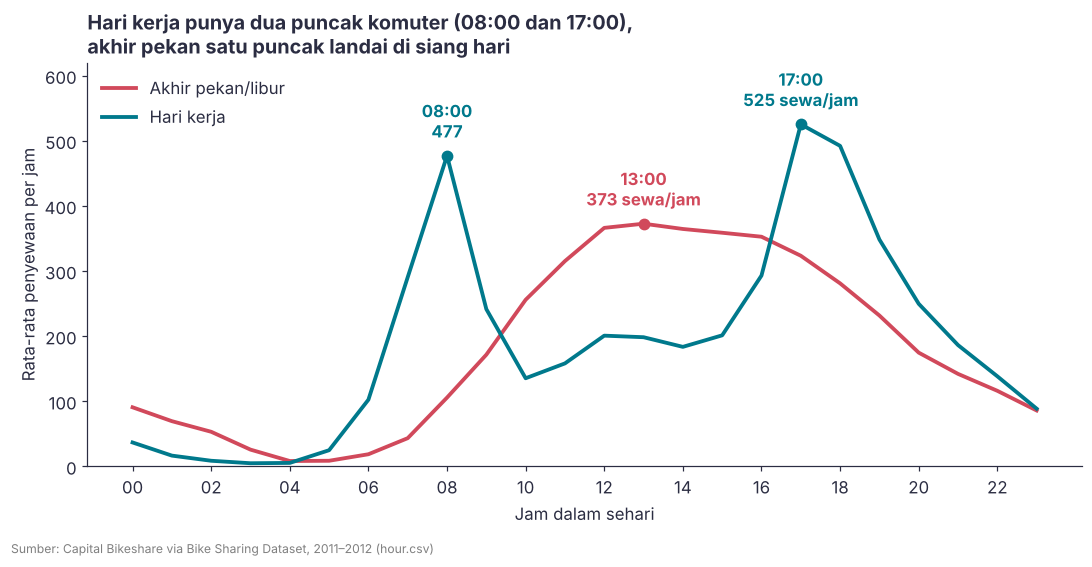

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hourly.index, hourly['Akhir Pekan/Libur'], color=C_HIGHLIGHT, lw=2.5, label='Akhir pekan/libur')
ax.plot(hourly.index, hourly['Hari Kerja'], color=C_PRIMARY, lw=2.5, label='Hari kerja')

# Anotasi langsung pada puncak
for tipe, warna, dy in [('Hari Kerja', C_PRIMARY, 25), ('Akhir Pekan/Libur', C_HIGHLIGHT, 25)]:
    h_peak = hourly[tipe].idxmax(); v_peak = hourly[tipe].max()
    ax.scatter(h_peak, v_peak, color=warna, zorder=5, s=45)
    ax.annotate(f'{h_peak:02d}:00\n{v_peak:.0f} sewa/jam', (h_peak, v_peak), xytext=(0, 12),
                textcoords='offset points', ha='center', color=warna, fontweight='bold')
# puncak pagi hari kerja
v8 = hourly.loc[8, 'Hari Kerja']
ax.scatter(8, v8, color=C_PRIMARY, zorder=5, s=45)
ax.annotate(f'08:00\n{v8:.0f}', (8, v8), xytext=(0, 12), textcoords='offset points', ha='center', color=C_PRIMARY, fontweight='bold')

ax.set_title('Hari kerja punya dua puncak komuter (08:00 dan 17:00),\nakhir pekan satu puncak landai di siang hari')
ax.set_xlabel('Jam dalam sehari'); ax.set_ylabel('Rata-rata penyewaan per jam')
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels([f'{h:02d}' for h in range(0, 24, 2)])
ax.set_ylim(0, 620); ax.yaxis.set_major_formatter(thousand)
ax.legend(frameon=False, loc='upper left')
fig.text(0.01, -0.02, 'Sumber: Capital Bikeshare via Bike Sharing Dataset, 2011–2012 (hour.csv)', fontsize=8, color='gray')
plt.tight_layout(); plt.show()

### Pertanyaan 2: Seberapa besar (dalam %) rata-rata penyewaan harian turun saat cuaca berkabut/berawan dan hujan/salju ringan dibandingkan saat cerah, serta pada rentang suhu aktual (°C) berapa rata-rata penyewaan harian paling tinggi selama 2011–2012, agar tim dapat menjadwalkan perawatan armada dan promosi berbasis cuaca?

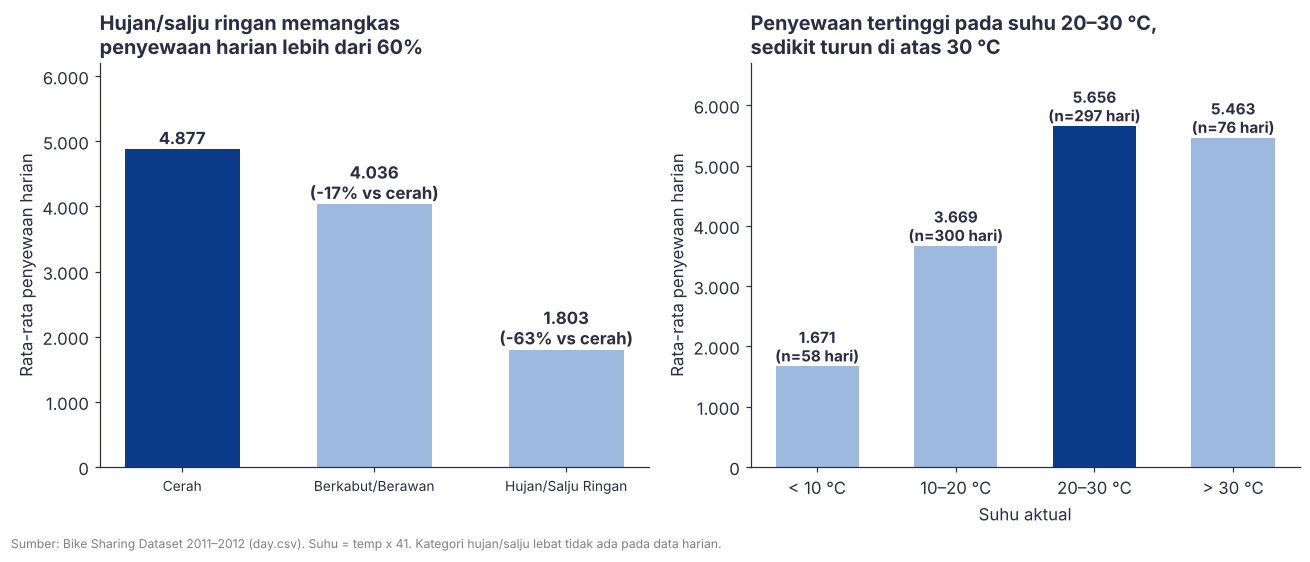

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel kiri: cuaca
w = weather_tbl.reset_index()
colors = [C_DARK if v == w['rata_rata'].max() else C_LIGHT for v in w['rata_rata']]
bars = axes[0].bar(w['weather'], w['rata_rata'], color=colors, width=0.6)
for b, pct in zip(bars, w['selisih_vs_cerah_%']):
    lbl = f"{b.get_height():,.0f}".replace(',', '.') + ('' if pct == 0 else f'\n({pct:+.0f}% vs cerah)')
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 80, lbl, ha='center', fontweight='bold')
axes[0].set_title('Hujan/salju ringan memangkas\npenyewaan harian lebih dari 60%')
axes[0].set_ylabel('Rata-rata penyewaan harian'); axes[0].set_ylim(0, 6200)
axes[0].yaxis.set_major_formatter(thousand)
axes[0].tick_params(axis='x', labelsize=9)

# Panel kanan: suhu
t = temp_tbl.reset_index()
best = t['rata_rata'].idxmax()
colors = [C_DARK if i == best else C_LIGHT for i in range(len(t))]
bars = axes[1].bar(t['temp_bin'].astype(str), t['rata_rata'], color=colors, width=0.6)
for b, n in zip(bars, t['jumlah_hari']):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 80,
                 f"{b.get_height():,.0f}".replace(',', '.') + f'\n(n={n} hari)', ha='center', fontweight='bold', fontsize=10)
axes[1].set_title('Penyewaan tertinggi pada suhu 20–30 °C,\nsedikit turun di atas 30 °C')
axes[1].set_ylabel('Rata-rata penyewaan harian'); axes[1].set_ylim(0, 6700)
axes[1].yaxis.set_major_formatter(thousand)
axes[1].set_xlabel('Suhu aktual')

fig.text(0.01, -0.01, 'Sumber: Bike Sharing Dataset 2011–2012 (day.csv). Suhu = temp x 41. Kategori hujan/salju lebat tidak ada pada data harian.', fontsize=8, color='gray')
plt.tight_layout(); plt.show()

### Pertanyaan 3: Berapa pertumbuhan total penyewaan bulanan 2012 dibanding bulan yang sama di 2011 (Year-over-Year), dan berapa proporsi pengguna kasual terhadap total pengguna di setiap musim, untuk menentukan musim yang paling tepat bagi kampanye konversi pengguna kasual menjadi anggota terdaftar?

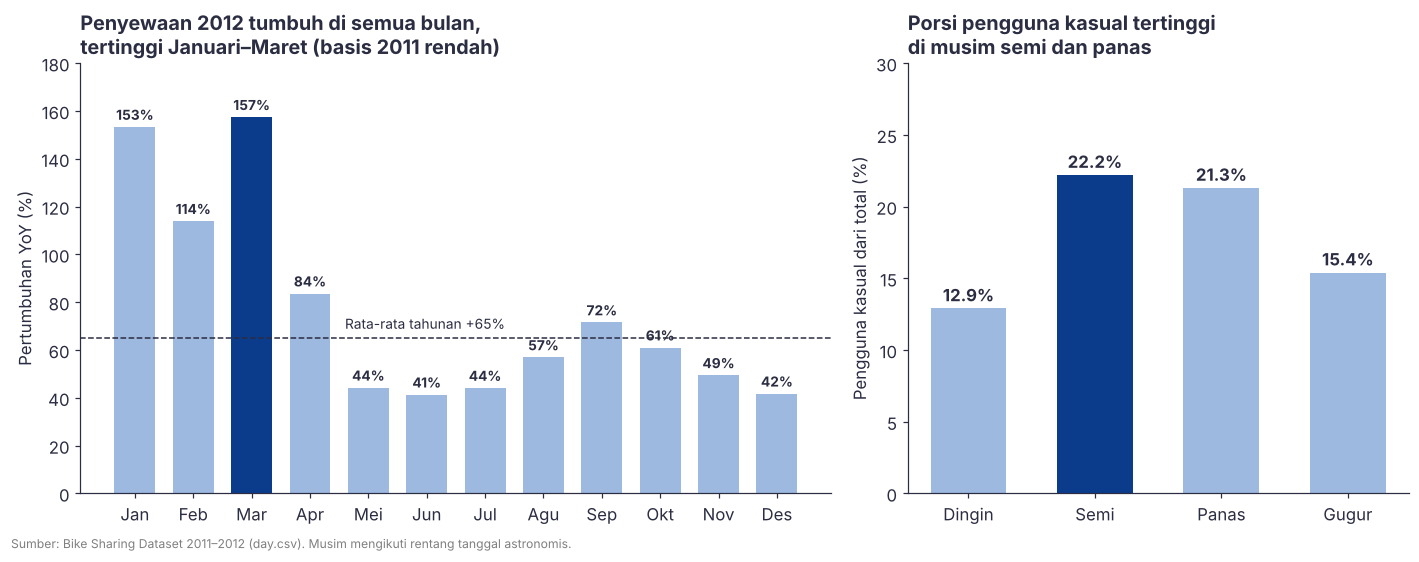

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.5, 1]})

# Panel kiri: pertumbuhan YoY per bulan
m = monthly.reset_index().rename(columns={'index': 'bulan'})
colors = [C_DARK if v == m['yoy_%'].max() else C_LIGHT for v in m['yoy_%']]
bars = axes[0].bar(m['bulan'], m['yoy_%'], color=colors, width=0.7)
for b, v in zip(bars, m['yoy_%']):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 3, f'{v:.0f}%', ha='center', fontsize=9, fontweight='bold')
axes[0].axhline(tot[2012] / tot[2011] * 100 - 100, color=C_TEXT, ls='--', lw=1)
axes[0].text(3.6, tot[2012] / tot[2011] * 100 - 100 + 4, f'Rata-rata tahunan +{(tot[2012] / tot[2011] - 1) * 100:.0f}%', ha='left', fontsize=9)
axes[0].set_title('Penyewaan 2012 tumbuh di semua bulan,\ntertinggi Januari–Maret (basis 2011 rendah)')
axes[0].set_ylabel('Pertumbuhan YoY (%)'); axes[0].set_ylim(0, 180)

# Panel kanan: porsi pengguna kasual per musim
s = season_users.reset_index()
best = s['casual_%'].idxmax()
colors = [C_DARK if i == best else C_LIGHT for i in range(len(s))]
bars = axes[1].bar(s['season_name'], s['casual_%'], color=colors, width=0.6)
for b, v in zip(bars, s['casual_%']):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].set_title('Porsi pengguna kasual tertinggi\ndi musim semi dan panas')
axes[1].set_ylabel('Pengguna kasual dari total (%)'); axes[1].set_ylim(0, 30)

fig.text(0.01, -0.01, 'Sumber: Bike Sharing Dataset 2011–2012 (day.csv). Musim mengikuti rentang tanggal astronomis.', fontsize=8, color='gray')
plt.tight_layout(); plt.show()

**Insight:**
- **P1:** Permintaan hari kerja ditentukan jam komuter (pagi dan sore); akhir pekan lebih merata di siang hari dengan puncak yang lebih rendah.
- **P2:** Cuaca buruk dan suhu rendah menekan permintaan secara tajam, sedangkan suhu hangat (20–30 °C) adalah kondisi terbaik.
- **P3:** Pertumbuhan 2012 terjadi merata, dan pengguna kasual paling menonjol di musim hangat, saat paparan calon anggota baru paling besar.

## Analisis Lanjutan (Opsional)

**Teknik: Manual Grouping dan Binning.** RFM tidak relevan karena dataset tidak memuat identitas pelanggan, dan analisis geospasial tidak memungkinkan karena tidak ada data lokasi. Teknik yang relevan adalah **Manual Grouping** (mengelompokkan jam menjadi segmen waktu berdasarkan aturan domain) dan **Binning** (`pd.cut`) untuk mengelompokkan tingkat permintaan per jam menjadi tier Rendah/Sedang/Tinggi/Sangat Tinggi. Tujuannya menghasilkan peta kebutuhan armada per segmen waktu dan tipe hari, tanpa algoritma machine learning.

In [23]:
# 1) Manual grouping: segmen waktu berdasarkan aturan domain
def segment(h):
    if h <= 5:  return '1. Dini hari (00–05)'
    if h <= 9:  return '2. Jam sibuk pagi (06–09)'
    if h <= 15: return '3. Siang (10–15)'
    if h <= 19: return '4. Jam sibuk sore (16–19)'
    return '5. Malam (20–23)'

hour_clean['time_segment'] = hour_clean['hr'].apply(segment)

# 2) Binning: tier permintaan per jam (ambang batas ditetapkan berdasarkan kapasitas operasional)
tier_bins = [-1, 100, 250, 400, np.inf]
tier_labels = ['Rendah (<100)', 'Sedang (100–250)', 'Tinggi (250–400)', 'Sangat Tinggi (>400)']
avg_hour = hour_clean.groupby(['day_type', 'hr'])['cnt'].mean().reset_index()
avg_hour['tier'] = pd.cut(avg_hour['cnt'], bins=tier_bins, labels=tier_labels)

tier_tbl = (avg_hour.groupby(['day_type', 'tier'], observed=False)['hr']
            .apply(lambda s: ', '.join(f'{h:02d}' for h in s) if len(s) else '-').unstack('day_type'))
tier_tbl

day_type,Akhir Pekan/Libur,Hari Kerja
tier,,
Rendah (<100),"00, 01, 02, 03, 04, 05, 06, 07, 23","00, 01, 02, 03, 04, 05, 23"
Sedang (100–250),"08, 09, 19, 20, 21, 22","06, 09, 10, 11, 12, 13, 14, 15, 20, 21, 22"
Tinggi (250–400),"10, 11, 12, 13, 14, 15, 16, 17, 18","07, 16, 19"
Sangat Tinggi (>400),-,"08, 17, 18"


In [24]:
seg_tbl = (hour_clean.groupby(['time_segment', 'day_type'])['cnt'].mean().unstack('day_type').round(0))
seg_tbl['selisih_hk_vs_libur'] = seg_tbl['Hari Kerja'] - seg_tbl['Akhir Pekan/Libur']

# Porsi tiap segmen terhadap total penyewaan per tipe hari
share = (hour_clean.groupby(['time_segment', 'day_type'])['cnt'].sum().unstack('day_type'))
share = (share / share.sum() * 100).round(1).add_suffix(' (% total)')
pd.concat([seg_tbl, share], axis=1)

day_type,Akhir Pekan/Libur,Hari Kerja,selisih_hk_vs_libur,Akhir Pekan/Libur (% total),Hari Kerja (% total)
time_segment,,,,,
1. Dini hari (00–05),43.0,16.0,-27.0,5.9,2.1
2. Jam sibuk pagi (06–09),85.0,278.0,193.0,7.8,24.1
3. Siang (10–15),339.0,180.0,-159.0,47.0,23.4
4. Jam sibuk sore (16–19),297.0,415.0,118.0,27.4,36.1
5. Malam (20–23),130.0,166.0,36.0,11.9,14.4


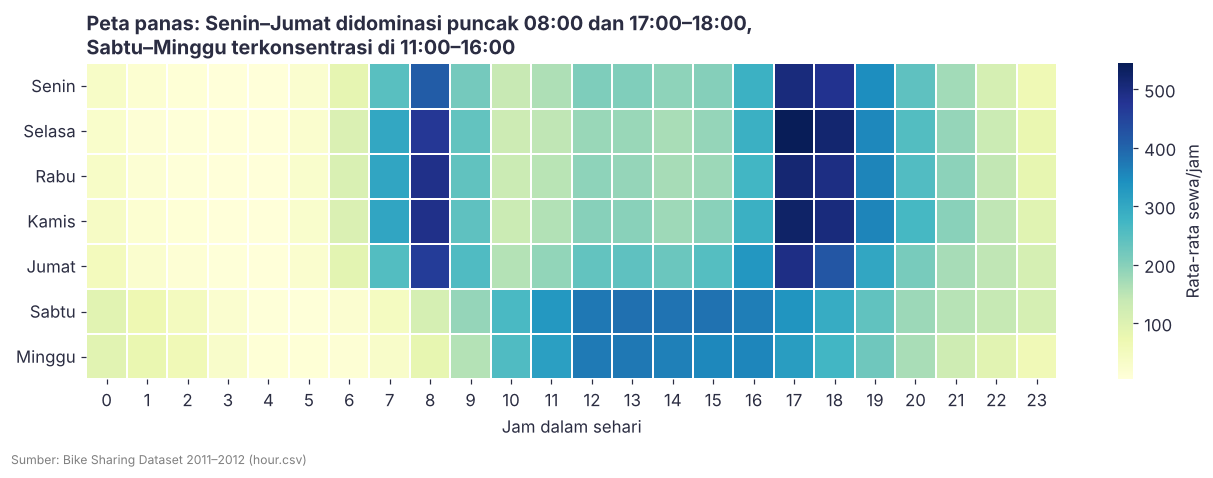

In [25]:
# Visualisasi: heatmap rata-rata penyewaan per jam x hari dalam seminggu
order = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
heat = hour_clean.pivot_table(index='weekday_name', columns='hr', values='cnt', aggfunc='mean').loc[order]

fig, ax = plt.subplots(figsize=(12, 4.2))
sns.heatmap(heat, cmap='YlGnBu', ax=ax, cbar_kws={'label': 'Rata-rata sewa/jam'}, linewidths=0.3, linecolor='white')
ax.set_title('Peta panas: Senin–Jumat didominasi puncak 08:00 dan 17:00–18:00,\nSabtu–Minggu terkonsentrasi di 11:00–16:00')
ax.set_xlabel('Jam dalam sehari'); ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
fig.text(0.01, -0.02, 'Sumber: Bike Sharing Dataset 2011–2012 (hour.csv)', fontsize=8, color='gray')
plt.tight_layout(); plt.show()

**Insight:**
- Pengelompokan jam menjadi segmen dan tier menunjukkan bahwa kebutuhan armada tidak merata: pada hari kerja, dua jam sibuk (06–09 dan 16–19) menyumbang ±60% total sewa (24% + 36%), sedangkan pada akhir pekan segmen siang (10–15) saja menyumbang ±47%.
- Tier **Sangat Tinggi** pada hari kerja terkonsentrasi di jam sibuk pagi dan sore, sedangkan pada akhir pekan tidak ada satu pun jam yang mencapai tier tersebut (puncaknya hanya masuk tier Tinggi).
- Peta panas memperlihatkan pola yang sama secara visual, dengan Jumat sedikit berbeda: puncak sore lebih landai (±421 sewa pada 18:00 dibanding ±481–518 pada Senin–Kamis) dan siang hari lebih tinggi (±240 pada 12:00–13:00 dibanding ±183–208).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Puncak penyewaan hari kerja terjadi pukul **17:00** (±525 sewa/jam), dengan puncak pagi kedua pukul **08:00** (±477). Akhir pekan/libur memuncak pukul **13:00** (±373). Selisih puncak ±153 sepeda/jam, atau sekitar 41% lebih tinggi di hari kerja. Pola dua puncak pada hari kerja menunjukkan penggunaan sebagai moda komuter.
- **Conclusion pertanyaan 2:** Dibanding hari cerah (±4.877 sewa/hari), penyewaan turun sekitar **17%** saat berkabut/berawan (±4.036) dan sekitar **63%** saat hujan/salju ringan (±1.803). Penyewaan tertinggi ada pada rentang **20–30 °C** (±5.656 sewa/hari), sementara di bawah 10 °C hanya ±1.671 sewa/hari. Di atas 30 °C penyewaan sedikit turun (±5.463).
- **Conclusion pertanyaan 3:** Total penyewaan 2012 tumbuh sekitar **65%** dibanding 2011 (1,24 juta menjadi 2,05 juta), dengan pertumbuhan YoY tertinggi pada Maret (±157%) dan terendah pada Juni (±41%). Pengguna kasual berkontribusi paling besar pada musim **semi dan panas** (sekitar 21–22% dari total), dan terkecil pada musim dingin (sekitar 13%).

**Rekomendasi Action Item:**
- **Redistribusi sepeda terjadwal:** pindahkan sepeda ke area permukiman sebelum 08:00 dan ke area perkantoran/stasiun sebelum 17:00 pada hari kerja; pada akhir pekan fokus ke area wisata/taman pukul 11:00–16:00.
- **Perawatan armada berbasis cuaca:** jadwalkan servis massal pada hari yang diprakirakan hujan atau bersuhu di bawah 10 °C, saat permintaan turun lebih dari 60%.
- **Promosi berbasis suhu:** perkuat promosi dan ketersediaan armada saat suhu 20–30 °C, dan pertimbangkan promo diskon di cuaca berkabut untuk menahan penurunan permintaan.
- **Kampanye konversi keanggotaan di musim semi dan panas:** tawarkan promo upgrade dari pengguna kasual ke anggota terdaftar saat porsi pengguna kasual paling tinggi.
- **Siapkan protokol cuaca ekstrem:** hari seperti 2012-10-29 (badai Sandy, hanya 22 sewa) perlu rencana operasional khusus untuk menjaga keselamatan armada dan staf.

**Keterbatasan:**
- Data hanya mencakup dua tahun dan satu kota, sehingga pola jangka panjang belum teruji.
- Pertumbuhan 2012 mungkin dipengaruhi ekspansi sistem (jumlah stasiun/sepeda), yang tidak tersedia pada dataset.
- Analisis bersifat deskriptif: hubungan antarvariabel tidak otomatis berarti sebab-akibat, dan ambang tier permintaan bersifat asumsi operasional.